In [1]:
# conda env spec

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4 as nc
from sklearn.linear_model import LinearRegression

In [2]:
def plot_time_point(data, time, ax, color='tab:orange'):
    tmp_data = data.sel(time=time).copy(deep=True)
    c = ax.scatter(tmp_data.Longitude.data, tmp_data.Latitude.data, s=20, marker='*', c=color, label=time)

In [3]:
obs_file = '../intermediate_data/MISR_OBS_CAMP2Ex_RF17.nc'
obs = xr.load_dataset(obs_file, engine='netcdf4')

sm_obs_file = '../intermediate_data/MISR_OBS_CAMP2Ex_RF17_Pris.nc'
sm_obs = xr.load_dataset(sm_obs_file, engine='netcdf4')

cth_file = '../intermediate_data/MISR_CTH_CAMP2Ex_RF17.nc'
cth = xr.load_dataset(cth_file)

bulk_props_file = '../../data/CAMP2Ex_SPEC/CAMP2Ex-CloudBulkProps_P3B_20191001_R0.ICT'
nav_file = '../../data/CAMP2Ex_SPEC/CAMP2EX-MetNav_P3B_20191001_R0.ict'
bulk_props = pd.read_csv(bulk_props_file, skiprows=37, header=0, index_col=0)
nav = pd.read_csv(nav_file, skiprows=73, header=0, index_col=0)
bulk_props.index = pd.to_datetime(bulk_props.index, unit='s', origin=pd.Timestamp('2019-10-01'))
bulk_props.index.name = 'time'
bulk_props = bulk_props.to_xarray()
nav.index = pd.to_datetime(nav.index, unit='s', origin=pd.Timestamp('2019-10-01'))
nav.index.name = 'time'
nav = nav.to_xarray()
p3 = xr.merge([bulk_props, nav])
nan_reff = p3.Reff_um.copy(deep=True).data
nan_reff[nan_reff == 0] = np.nan
p3['Reff_um'] = (['time'], nan_reff)
p3['ext_km'] = (3 * 1e-3 * p3.LWC_gm3) / (2 * 997 * 1e-9 * p3.Reff_um)
aerosols = np.zeros(p3.time.data.shape)
aerosols[(p3.time.data < np.datetime64('2019-10-02T00:02:00'))] = np.nan
aerosols[(p3.time.data >= np.datetime64('2019-10-02T00:02:00')) & (p3.time.data < np.datetime64('2019-10-02T00:07:00'))] = 1
aerosols[(p3.time.data >= np.datetime64('2019-10-02T00:07:00')) & (p3.time.data < np.datetime64('2019-10-02T00:13:00'))] = 2
aerosols[(p3.time.data >= np.datetime64('2019-10-02T00:12:00')) & (p3.time.data < np.datetime64('2019-10-02T00:16:00'))] = 1
aerosols[(p3.time.data >= np.datetime64('2019-10-02T00:16:00')) & (p3.time.data < np.datetime64('2019-10-02T00:56:00'))] = 0
aerosols[(p3.time.data >= np.datetime64('2019-10-02T00:56:00')) & (p3.time.data < np.datetime64('2019-10-02T01:02:00'))] = 1
aerosols[(p3.time.data >= np.datetime64('2019-10-02T01:02:00')) & (p3.time.data < np.datetime64('2019-10-02T01:28:00'))] = 2
aerosols[(p3.time.data >= np.datetime64('2019-10-02T01:28:00')) & (p3.time.data < np.datetime64('2019-10-02T01:33:00'))] = 1
aerosols[(p3.time.data >= np.datetime64('2019-10-02T01:33:00')) & (p3.time.data < np.datetime64('2019-10-02T02:00:00'))] = 2
aerosols[(p3.time.data >= np.datetime64('2019-10-02T02:00:00'))] = np.nan

p3['aerosols'] = (['time'], aerosols)
p3.to_netcdf('../../data/CAMP2Ex_SPEC/RF17_preprocessed.nc')
p3 = p3.sel(time=slice('2019-10-02T00:00:00', '2019-10-02T01:50:00'))

aerosol_file = '../../data/MISR/MISR_AM1_AS_AEROSOL_P117_O105254_F13_0023.nc'
dataset = nc.Dataset(aerosol_file,'r')
products = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset['/4.4_KM_PRODUCTS/']))
aux = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset['/4.4_KM_PRODUCTS/AUXILIARY/']))
merged = xr.merge([products, aux])
aerosol_ds = merged.sel(X_Dim=slice(1.774e7,1.816e7), Y_Dim=slice(-0.6e6, 0.6e6)).copy(deep=True)
aerosol_ds['aod670'] = aerosol_ds.Aerosol_Optical_Depth * (0.67 / 0.55) ** aerosol_ds.Angstrom_Exponent_550_860nm


In [4]:
pristine = p3.aerosols.data == 0
trans = p3.aerosols.data == 1
polluted = p3.aerosols.data == 2

prist_color = 'tab:green'
trans_color = 'tab:gray'
poll_color = 'tab:brown'

cth_cmap = 'magma'
aod_cmap = 'copper'
# aod_cmap = 'pink_r'

Text(0, 0.5, 'Latitude')

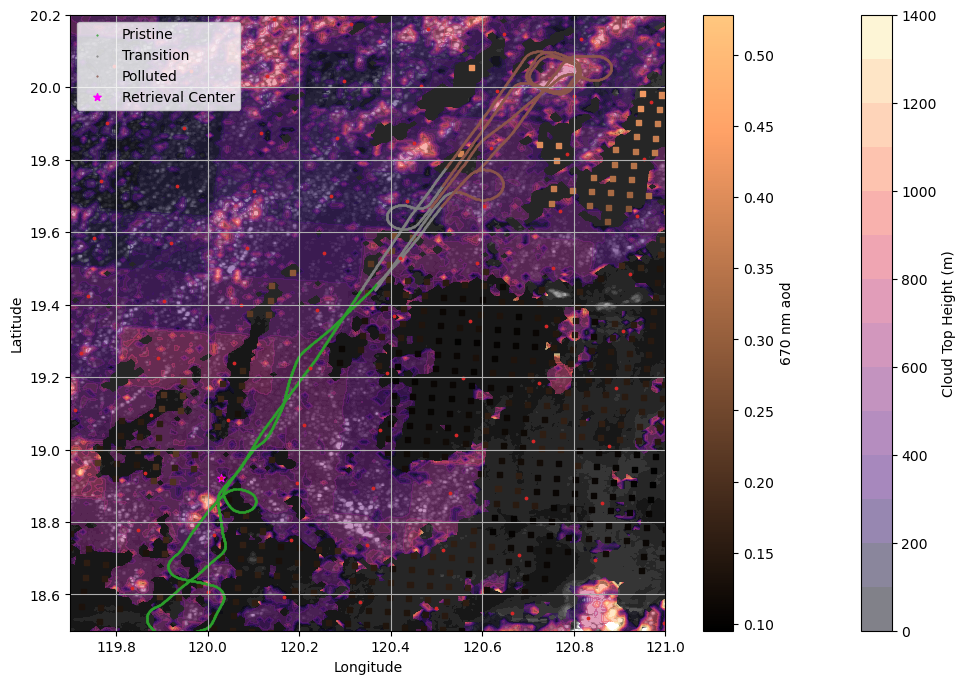

In [5]:
f, ax = plt.subplots(1, 1, figsize=(12,8))

# Plot MISR BRF & 17.6 km sampling
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.25, cmap='gray', levels=100)

# Plot MISR CTH
levels = np.arange(0, 1500, 100)
cth_ax = ax.contourf(cth.lon1100.data, cth.lat1100.data, cth.cth.data, alpha=0.5, vmin=0, vmax=1400, levels=levels, cmap=cth_cmap)
plt.colorbar(cth_ax, label='Cloud Top Height (m)')

# Plot MISR aerosols
as_lon = np.ravel(aerosol_ds.Longitude.data)
as_lat = np.ravel(aerosol_ds.Latitude.data)
aod = ax.scatter(as_lon, as_lat, c=aerosol_ds.aod670.data, s=13, alpha=1.0, marker='s', vmin=None, vmax=None, cmap=aod_cmap)
plt.colorbar(aod, label='670 nm aod')

# Plot P3 Flight tracks
p3track_size = 0.25
ax.scatter(p3.Longitude.data[pristine], p3.Latitude.data[pristine], s=p3track_size, c=prist_color, label='Pristine')
ax.scatter(p3.Longitude.data[trans], p3.Latitude.data[trans], s=p3track_size, c=trans_color, label='Transition')
ax.scatter(p3.Longitude.data[polluted], p3.Latitude.data[polluted], s=p3track_size, c=poll_color, label='Polluted')
# ax.scatter(p3.Longitude.data[0], p3.Latitude.data[0], s=10, c='tab:green', marker='x', label='Start: {}'.format(p3.time.data[0]))
# ax.scatter(p3.Longitude.data[-1], p3.Latitude.data[-1], s=10, c='tab:red', marker='x', label='End: {}'.format(p3.time.data[-1]))

# Plot SPEC samples
# spec_re = ax.scatter(p3.Longitude.data, p3.Latitude.data, s=7, alpha=1.0, c=p3.Reff_um.data, cmap='cividis')
# plt.colorbar(spec_re, label='Reff (um)')

# Plot AT3D retreival center & sampling points
ax.scatter(sm_obs.center_lon.data, sm_obs.center_lat.data, marker='*', c='fuchsia', s=30, label='Retrieval Center')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')

# Adjust window
# ax.set_xlim([118, 123])
# ax.set_ylim([17.4, 21.5])
# ax.set_xlim([119.2, 121.6])
# ax.set_ylim([18.0, 20.8])
ax.set_xlim([119.7, 121.0])
ax.set_ylim([18.5, 20.2])
ax.grid()
ax.legend(loc='upper left')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

Text(0, 0.5, 'Latitude')

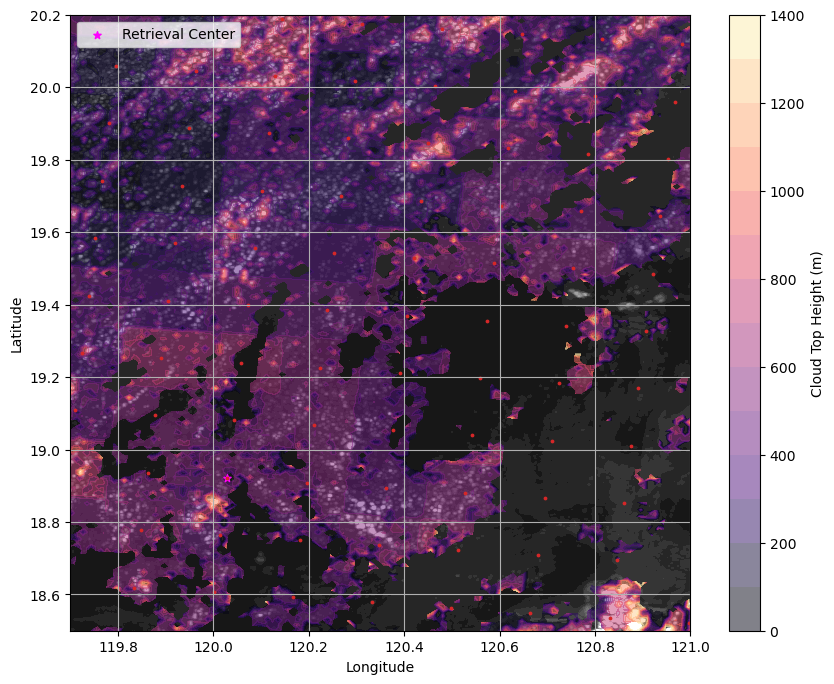

In [6]:
f, ax = plt.subplots(1, 1, figsize=(10,8))

# Plot MISR BRF & 17.6 km sampling
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.25, cmap='gray', levels=100)

# Plot MISR CTH
levels = np.arange(0, 1500, 100)
cth_ax = ax.contourf(cth.lon1100.data, cth.lat1100.data, cth.cth.data, alpha=0.5, vmin=0, vmax=1400, levels=levels, cmap=cth_cmap)
plt.colorbar(cth_ax, label='Cloud Top Height (m)')

# Plot MISR aerosols
# as_lon = np.ravel(aerosol_ds.Longitude.data)
# as_lat = np.ravel(aerosol_ds.Latitude.data)
# aod = ax.scatter(as_lon, as_lat, c=aerosol_ds.aod670.data, s=13, alpha=1.0, marker='s', vmin=None, vmax=None, cmap=aod_cmap)
# plt.colorbar(aod, label='670 nm aod')

# # Plot P3 Flight tracks
# p3track_size = 2
# ax.scatter(p3.Longitude.data[pristine], p3.Latitude.data[pristine], s=p3track_size, c=prist_color, label='Pristine')
# ax.scatter(p3.Longitude.data[trans], p3.Latitude.data[trans], s=p3track_size, c=trans_color, label='Transition')
# ax.scatter(p3.Longitude.data[polluted], p3.Latitude.data[polluted], s=p3track_size, c=poll_color, label='Polluted')
# # ax.scatter(p3.Longitude.data[0], p3.Latitude.data[0], s=10, c='tab:green', marker='x', label='Start: {}'.format(p3.time.data[0]))
# # ax.scatter(p3.Longitude.data[-1], p3.Latitude.data[-1], s=10, c='tab:red', marker='x', label='End: {}'.format(p3.time.data[-1]))

# Plot SPEC samples
# spec_re = ax.scatter(p3.Longitude.data, p3.Latitude.data, s=7, alpha=1.0, c=p3.Reff_um.data, cmap='cividis')
# plt.colorbar(spec_re, label='Reff (um)')

# Plot AT3D retreival center & sampling points
ax.scatter(sm_obs.center_lon.data, sm_obs.center_lat.data, marker='*', c='fuchsia', s=30, label='Retrieval Center')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')

# Adjust window
# ax.set_xlim([118, 123])
# ax.set_ylim([17.4, 21.5])
# ax.set_xlim([119.2, 121.6])
# ax.set_ylim([18.0, 20.8])
ax.set_xlim([119.7, 121.0])
ax.set_ylim([18.5, 20.2])
ax.grid()
ax.legend(loc='upper left')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

Text(0, 0.5, 'altitude (m)')

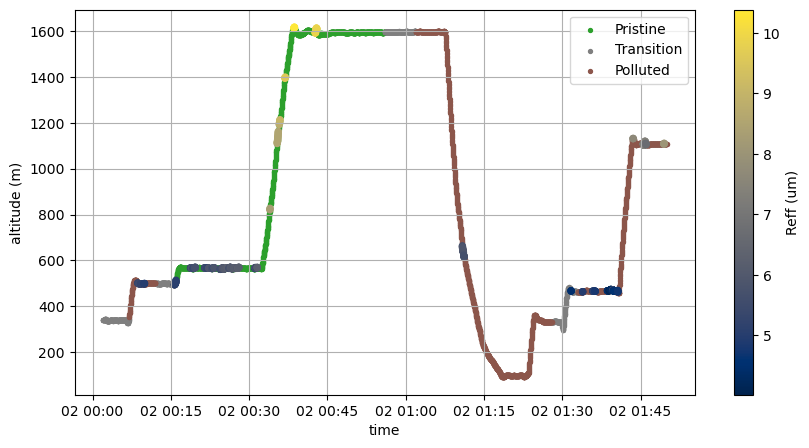

In [7]:
f, ax = plt.subplots(1, 1, figsize=(10,5))
size = 8
ax.scatter(p3.time.data[pristine], p3.GPS_Altitude.data[pristine], s=size, c=prist_color, label='Pristine')
ax.scatter(p3.time.data[trans], p3.GPS_Altitude.data[trans], s=size, c=trans_color, label='Transition')
ax.scatter(p3.time.data[polluted], p3.GPS_Altitude.data[polluted], s=size, c=poll_color, label='Polluted')
p3_reff = ax.scatter(p3.time.data, p3.GPS_Altitude.data, s=size+11, c=p3.Reff_um.data, cmap='cividis')
plt.colorbar(p3_reff, ax=ax, label='Reff (um)')
ax.legend()
ax.grid()
ax.set_xlabel('time')
ax.set_ylabel('altitude (m)')

In [8]:
# Prepare the data
y = p3['Reff_um'].data
cloud_cond = ~np.isnan(y)
y_cloud = y[cloud_cond]
y_pris = y[cloud_cond & pristine]
y_poll = y[cloud_cond & polluted]
X = p3['GPS_Altitude'].data / 1000
X_cloud = X[cloud_cond].reshape(-1, 1)
X_pris = X[cloud_cond & pristine].reshape(-1, 1)
X_poll = X[cloud_cond & polluted].reshape(-1, 1)

# Create an instance of the LinearRegression model
m_cloud = LinearRegression()
m_pris = LinearRegression()
m_poll = LinearRegression()

# Fit the model to the data
m_cloud.fit(X_cloud, y_cloud)
m_pris.fit(X_pris, y_pris)
m_poll.fit(X_poll, y_poll)

# Print the regression results
print('All Cloud:')
print("   Intercept:", m_cloud.intercept_)
print("   Coefficient:", m_cloud.coef_)
print('Pristine:')
print("   Intercept:", m_pris.intercept_)
print("   Coefficient:", m_pris.coef_)
print('All Cloud:')
print("   Intercept:", m_poll.intercept_)
print("   Coefficient:", m_poll.coef_)

All Cloud:
   Intercept: 2.991867942556189
   Coefficient: [4.41088483]
Pristine:
   Intercept: 3.4640699891784057
   Coefficient: [4.21285275]
All Cloud:
   Intercept: 2.6225217705851955
   Coefficient: [4.29198287]


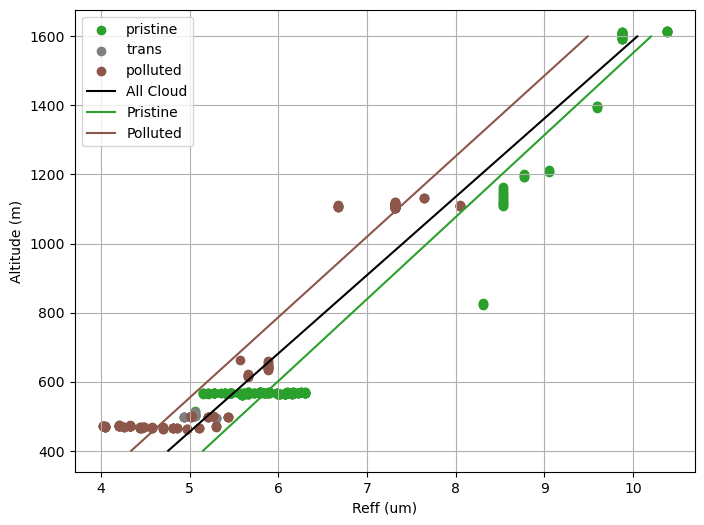

In [9]:
f, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(p3.Reff_um.data[pristine], p3.GPS_Altitude[pristine], c=prist_color, label='pristine')
ax.scatter(p3.Reff_um.data[trans], p3.GPS_Altitude[trans], c=trans_color, label='trans')
ax.scatter(p3.Reff_um.data[polluted], p3.GPS_Altitude[polluted], c=poll_color, label='polluted')

z = np.linspace(400, 1600, 200)
re_cloud = m_cloud.intercept_ + m_cloud.coef_ * z/1000
re_pris = m_pris.intercept_ + m_pris.coef_ * z/1000
re_poll = m_poll.intercept_ + m_poll.coef_ * z/1000

ax.plot(re_cloud, z, color='black', label='All Cloud')
ax.plot(re_pris, z, color=prist_color, label='Pristine')
ax.plot(re_poll, z, color=poll_color, label='Polluted')
ax.set_xlabel('Reff (um)')
ax.set_ylabel('Altitude (m)')
ax.grid()
ax.legend()
# ax.set_xlim(0, 28)
# ax.set_ylim(0, 1200)


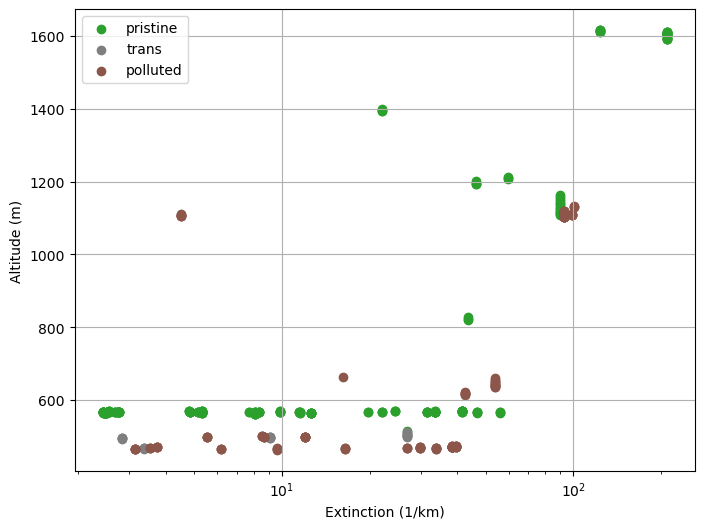

In [10]:
f, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(p3.ext_km.data[pristine], p3.GPS_Altitude[pristine], c=prist_color, label='pristine')
ax.scatter(p3.ext_km.data[trans], p3.GPS_Altitude[trans], c=trans_color, label='trans')
ax.scatter(p3.ext_km.data[polluted], p3.GPS_Altitude[polluted], c=poll_color, label='polluted')

ax.set_xlabel('Extinction (1/km)')
ax.set_ylabel('Altitude (m)')
ax.grid()
ax.legend()
ax.set_xscale('log')
